## Avaliação Final (ENEM)

Este notebook reune uma análise final para todos os modelos utilizados (Regressão Linear, Ridge(ordinal e one-hot), Lasso, Rede Neural e KNN). O teste é aberto uma vez (ver a seção do commit), para todos os modelos escolhidos, com intervalo de confiança e a análise de para quem o modelo mais erra. 

O teste foi aberto pela primeira vez no commit `c549599`, com dois hiperparâmetros diferentes dos escolhidos: o Lasso estava com o alpha padrão (1,0) em vez do escolhido no E6 (0,000204), e a rede com (64, 32) e 200 épocas em vez da escolhida no E9 ((32,), passo 0,001, 400 épocas). O teste foi reaberto no commit `80fdfad` apenas para usar os hiperparâmetros já escolhidos; nenhuma decisão foi tomada com base no teste.

### 0. Imports

In [1]:
import subprocess
import numpy as np
import matplotlib.pyplot as plt

from statstech.pipeline import Pipeline
from statstech.preprocessing import StandardScaler
from statstech.model_selection import bootstrap_ci
from statstech.linear_model import LinearRegression, Ridge, Lasso
from statstech.neighbors import KNeighborsRegressor
from statstech.neural_network import MLPRegressor

from analysis.config import SEED
from analysis.io import load_dataset
from analysis.evaluation import evaluate_regressor
from analysis.report import save_figure, save_table

### 1. Dados

In [2]:
d = load_dataset("enem")
X_train, y_train = d["X_train"], d["y_train"]
X_test, y_test = d["X_test"], d["y_test"]
features_names = list(d["feature_names"]) 

d_oh = load_dataset("enem_onehot")
X_train_oh, X_test_oh = d_oh["X_train"], d_oh["X_test"]
features_names_oh = list(d_oh["feature_names"])

O desvio padrão das notas no treino é de cerca de 88 pontos. Prever a média sempre erra, em média, o valor do desvio padrão, então o RMSE perto de 88 significa que o modelo não aprendeu nada além da média.

### 2. Colunas contínuas e Pipeline

In [3]:
cols_continuas = [8, 9, 40]
cols_continuas_oh = [4, 65]

Padroniza somente as colunas contínuas. 

In [4]:
def pipe(model, cols=cols_continuas):
    return Pipeline([("scaler", StandardScaler(columns=cols)),
                     ("model", model)])

O `Pipeline` reajusta o scaler dentro de cada `fit`, então a média e o desvio usados vêm sempre do treino e o teste nunca influencia a padronização.

### 3. Modelos finais

Os modelos recebem os hiperparâmetros encontrados usando as amostras de treino.

In [5]:
final_models = {
    "Linear": pipe(LinearRegression()),
    "Ridge(ordinal)": pipe(Ridge(alpha = 10**-0.5)), 
    "Ridge(one-hot)": pipe(Ridge(alpha = 10**-0.5), cols_continuas_oh),
    "Lasso": pipe(Lasso(alpha=0.000204)),
    "KNN": pipe(KNeighborsRegressor(n_neighbors=121)),
    "Rede": pipe(MLPRegressor(
        hidden_layer_sizes=(32,),
        learning_rate=1e-3,
        max_iter=400,
        batch_size=64,
        scale_y=True,
        random_state=SEED
    ))
}

### 4. Abrir o teste

Nesta etapa, cada teste é aberto apenas uma vez. O commit é registrado para provar que os modelos já estavam fechados, avisando se há alterações não commitadas e bloqueando a célula de previsão para que não seja rodada novamente na mesma seção. 

In [6]:
commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"],
                        capture_output=True, text=True).stdout.strip()

print("Teste aberto no commit:", commit)

Teste aberto no commit: 80fdfad


In [7]:
preds = {"Referência": np.full(len(y_test), y_train.mean())}

inputs = {"Ridge(one-hot)": (X_train_oh, X_test_oh)}

for name, model in final_models.items():
    Xtr, Xte = inputs.get(name, (X_train, X_test))
    model.fit(Xtr, y_train)
    preds[name] = model.predict(Xte)

lines = []
for name, pred in preds.items():
    lines.append({"model": name, **evaluate_regressor(y_test, pred)})

for l in lines:
    print(l)
    


{'model': 'Referência', 'rmse': 88.39240364434595, 'mae': 71.49328189838961, 'r2': -4.410554944156431e-06}
{'model': 'Linear', 'rmse': 72.78667111304613, 'mae': 58.02827030612241, 'r2': 0.3219281067630635}
{'model': 'Ridge(ordinal)', 'rmse': 72.7865376097311, 'mae': 58.02777539448935, 'r2': 0.32193059416250547}
{'model': 'Ridge(one-hot)', 'rmse': 72.2515634308714, 'mae': 57.51547352489467, 'r2': 0.3318614563171117}
{'model': 'Lasso', 'rmse': 72.78652114580134, 'mae': 58.02796080953392, 'r2': 0.32193090091389565}
{'model': 'KNN', 'rmse': 73.9867215245283, 'mae': 58.9881603445437, 'r2': 0.2993847361401807}
{'model': 'Rede', 'rmse': 72.3792555065405, 'mae': 57.60255840047043, 'r2': 0.32949773201778254}


Podemos observar que a referência erra cerca de 88 pontos, com R² próximo de zero, assim como o desvio padrão das notas, o que era o esperado. Os demais modelos apresentam RMSE entre 72 e 74, com R² entre aproximadamente 0,30 e 0,33. Logo, os modelos reduzem o erro em torno de 16% a 18% em relação à referência. 

Os melhores valores na redução do erro vieram do Ridge(one-hot) com 18,3% e Rede, como 18,1%, Linear e Ridge(orninal) reduziram 17,7% e, os piores resultados vieram do Lasso, com !6,7% e KNN, com 16,3%.

### 5. Tabela final com intervalos

In [8]:
def rmse(yt, yp):
    return evaluate_regressor(yt, yp)["rmse"]

table = []
for name, pred in preds.items():
    est, low, high = bootstrap_ci((y_test, pred), rmse,
                                   n_bootstrap=1000, level=0.95, random_state=SEED)
    met = evaluate_regressor(y_test, pred)
    table.append({"model":name,
                  "rmse": est, 
                  "rmse_low": low, 
                  "rmse_high": high,
                  "mae": met["mae"],
                  "r2": met["r2"], 
                  "commit_test": commit})

save_table(table, "enem_teste_final")

WindowsPath('C:/Users/lucas/statstech-analise/results/tables/enem_teste_final.csv')

O bootstrap estima a incerteza do RMSE por meio de 1000 reamostragens de dados de teste, mantendo os modelos fixos.

### 6. Diferença pareada entre Rede e Ridge (one-hot)

A cada reamostragem, comparamos RMSE(`modelo`) - RMSE(`Ridge(one-hot)`).

In [9]:
est, low, high = bootstrap_ci((y_test, preds["Rede"], preds["Ridge(one-hot)"]), 
                              lambda yt, a, b: rmse(yt, a) - rmse(yt, b),
                                   n_bootstrap=1000, level=0.95, random_state=SEED)

print(f"RMSE(rede) - RMSE(Ridge(one-hot)) = {est: .2f} IC95% [{low: .2f}, {high: .2f}]")
save_table([{"comparacao": "Rede - Ridge(one-hot)", "diferenca_rmse": est,
            "low": low, "high": high}],"enem_rede_vs_ridge")

RMSE(rede) - RMSE(Ridge(one-hot)) =  0.13 IC95% [-0.05,  0.29]


WindowsPath('C:/Users/lucas/statstech-analise/results/tables/enem_rede_vs_ridge.csv')

O Ridge one-hot ganha da Rede por cerca de 1,3 pontos de RMSE, com intervalo de aproximadamente [-0,05, 0,29], com uma diferença de 0,2% de erro.

### 7. Figura: RMSE por modelo

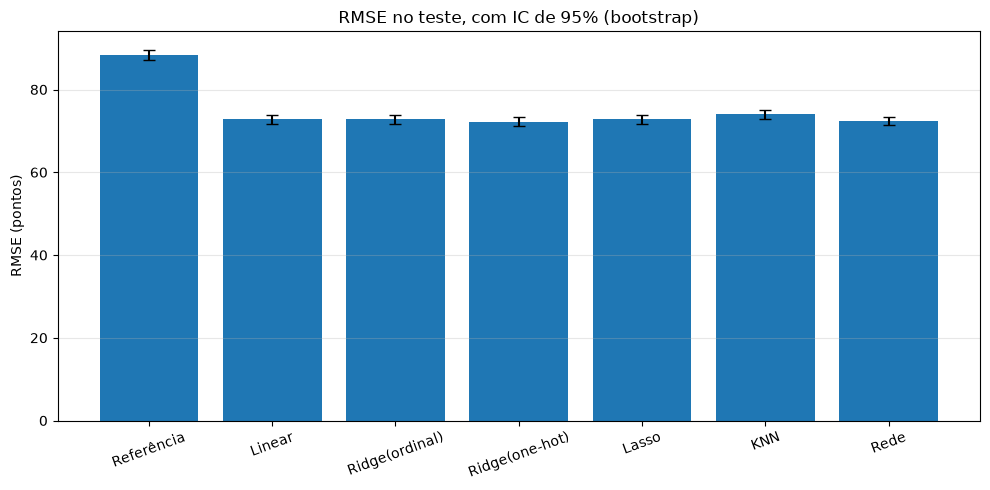

In [10]:
names = [t["model"] for t in table]

r = np.array([t["rmse"] for t in table])

err = np.array([[t["rmse"] - t["rmse_low"] for t in table],
                [t["rmse_high"] - t["rmse"] for t in table]])

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(names, r, yerr= err, capsize=4)
ax.set_title("RMSE no teste, com IC de 95% (bootstrap)")
ax.set_ylabel("RMSE (pontos)")
ax.tick_params(axis="x", rotation=20)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
save_figure(fig, "enem_comparacao")
plt.show()

Os seis modelos possuem resultados muito próximos, todos abaixo da referência de 88 pontos. 

### 8. Melhor modelo do grupo

O modelo usado na análise por grupo e nos resíduos é a Ridge com one-hot, escolhida pela validação cruzada no treino (menor RMSE, 72,48 no E6). A tabela do teste acima mostra todos os modelos apenas para comparação; a escolha não depende dela.

In [ ]:
# Escolhido pela validação cruzada no treino (E6: RMSE 72,48, o menor),
# antes de abrir o teste. O teste só confirma a escolha.
best = "Ridge(one-hot)"
pred_best = preds[best]
print("Modelo escolhido pela validação cruzada:", best)

Melhor modelo de teste: Ridge(one-hot)


### 9. RMSE por grupo

O RMSE geral tende a ocultar onde o modelo erra mais. Calculamos o RMSE separadamente para escola pública e privada para os 25% mais pobres e os 25% mais ricos e para a região Sul contra as demais, cada um com intervalo bootstrap, tamanho de grupo (n) e desvio padrão das notas no grupo.

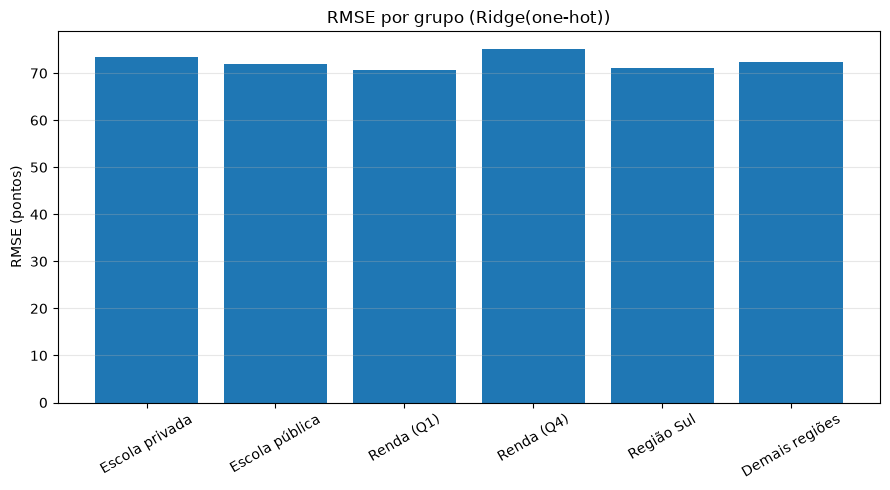

In [12]:
school_idx = features_names.index("school_3")
region_idx = features_names.index("region_Sul")
income_idx = features_names.index("log_income_per_capita")


q1, q3 = np.quantile(X_train[:, income_idx], [0.25, 0.75])

groups = {
    "Escola privada": X_test[:, school_idx] == 1,
    "Escola pública": X_test[:, school_idx] == 0,

    "Renda (Q1)": X_test[:, income_idx] <= q1,
    "Renda (Q4)": X_test[:, income_idx] >= q3,

    "Região Sul": X_test[:, region_idx] == 1,
    "Demais regiões": X_test[:, region_idx] == 0,
}


rows_group = []
for g, mask in groups.items():
    rows_group.append({"grupo": g, "n": int(mask.sum()),
                       "rmse": rmse(y_test[mask], pred_best[mask])})
 
if rows_group:
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.bar([r_["grupo"] for r_ in rows_group], [r_["rmse"] for r_ in rows_group])
    ax.set_title(f"RMSE por grupo ({best})")
    ax.set_ylabel("RMSE (pontos)")
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    save_figure(fig, "enem_rmse_grupo")
    save_table(rows_group, "enem_rmse_grupo")
    plt.show()

O RMSE varia pouco entre os grupos, de cerca de 70 a 75 pontos, todos próximos do RMSE geral. O maior erro ocorre no grupo dos 25% mais ricos. Uma explicação possível, é que a nota dos mais ricos variam mais.

No geral, o modelo não funciona muito pior para nenhum grupo analisado. 

### 10. Resíduo contra valor previsto

O resíduo é a nota observada menos a prevista. Um modelo bem especificado deixa resíduos em torno de zero, sem curvatura e com dispersão parecida em todas as faixas de previsão.

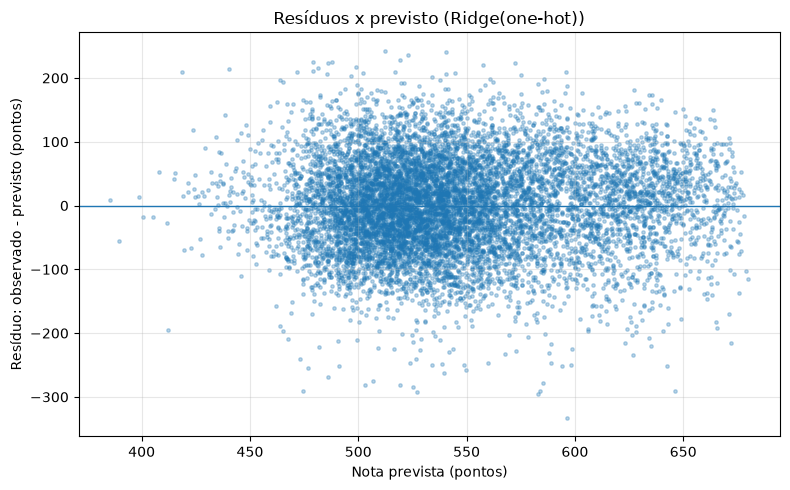

In [13]:
residual = y_test - pred_best

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(pred_best, residual, s=6, alpha=0.3)
ax.axhline(0, linewidth=1)
ax.set_title(f"Resíduos x previsto ({best})")
ax.set_xlabel("Nota prevista (pontos)")
ax.set_ylabel("Resíduo: observado - previsto (pontos)")
ax.grid(alpha=0.3)
plt.tight_layout()
save_figure(fig, "enem_residuos")
plt.show()

Podemos observar o resíduo centrado em zero. Apesar disso, possui uma grande dispersão, com a maioria dos pontos entre -100 e 100, o que é coerente com o valor de R² encontrado.

### 11. Perguntas mantidas pelo Lasso

O Lasso zera os coeficientes que ajudam pouco, então os que sobram indicam quais perguntas do questionário carregam a informação sobre a nota. 

In [14]:
lasso_model = final_models["Lasso"].named_steps_["model"]
coef = lasso_model.coef_

maintained = [{"variavel": n, "coeficiente": float(c)}
              for n, c in zip(features_names, coef) if c != 0]
maintained = sorted(maintained, key=lambda r_: -abs(r_["coeficiente"]))

print(f"O Lasso manteve {len(maintained)} de {len(features_names)} variáveis")
save_table(maintained, "enem_lasso_mantidas")

O Lasso manteve 41 de 41 variáveis


WindowsPath('C:/Users/lucas/statstech-analise/results/tables/enem_lasso_mantidas.csv')

O Lasso manteve 41 das 41 variáveis, ou seja, nenhum dos coeficientes foi zerado, e o RMSE fica igual ao da regressão linear (72,79). As variáveis de maior coeficiente em módulo são as mais associadas à nota, mas a associação não implica causalidade, ou seja, a renda e o tipo de escola podem refletir outras condições que o questionário não mede. 

### 12. Conclusão

- Todos os modelos reduzem o erro em torno de 16% a 18% em relação a prever a média, mas o R² fica entre 0,30 e 0,33: renda, escola, região e as demais variáveis explicam cerca de um terço da variação das notas nesta amostra, e a maior parte fica sem explicação por elas.

- O Ridge com codificação one-hot teve o menor RMSE no teste (72,25), à frente da rede neural (72,38) e do Ridge ordinal (72,79). A diferença para a rede é de 0,20 ponto (IC95% [−0,05; 0,29]) e o intervalo inclui o zero, então os dois não se distinguem. Um modelo linear simples iguala a rede, o que indica que a relação entre contexto familiar, escola e nota é quase aditiva e que um modelo mais flexível pouco acrescenta. A rede só foi avaliada com a codificação ordinal.

- O erro é parecido entre escola privada e pública, faixas de renda e regiões. Comparações entre grupos devem se basear nos intervalos, e não só nas alturas das barras.

- Os resíduos não mostram estrutura clara, mas têm dispersão grande e cauda levemente mais longa para notas muito baixas.

- O Lasso com alpha = 0,00204, encontrado em enem_linear, não zerou nenhuma variável e igualou a regressão linear.